# Compute the Connectome Spectrum Transform

For every connectome (which can be represented as a graph), there is an underlying connectome spectrum. In mathematical terms, the analysis involves computing the Graph Fourier Transform (GFT).

The GFT uses the eigenvectors of the Graph Laplacian matrix (often the Normalized Graph Laplacian) as its basis functions. These eigenvectors form the spectrum.
- The eigenvectors of the Graph Laplacian correspond to the modes or harmonics on the graph, analogous to the sine and cosine waves of the standard Euclidean Fourier Transform.
- Each eigenvector is associated with a corresponding eigenvalue. This eigenvalue represents the spatial frequency or the measure of variation of the eigenvector across the graph (i.e., how quickly the eigenvector changes value between connected nodes).

## 🧪 - Experiment setup
- `conn`: Structural Connectome
- `src`: Source Space

In [1]:
import pygsp
import mindmap as mm

# data manager
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"

# data
con = dm.load(sub, "con")
src = dm.load(sub, "fwd", desc="sim")["src"]

## 🧬 - Data Processing

Compute the Connectome Spectrum Transform (CST).

In [2]:
G = pygsp.graphs.Graph(con, lap_type="normalized")
G.compute_fourier_basis()

eigvec = G.U
eigval = G.e

2026-05-19 17:07:34,618:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (7399 x 7399) may take some time.


## 📊 - Visualization

Eigenvalue distribution.

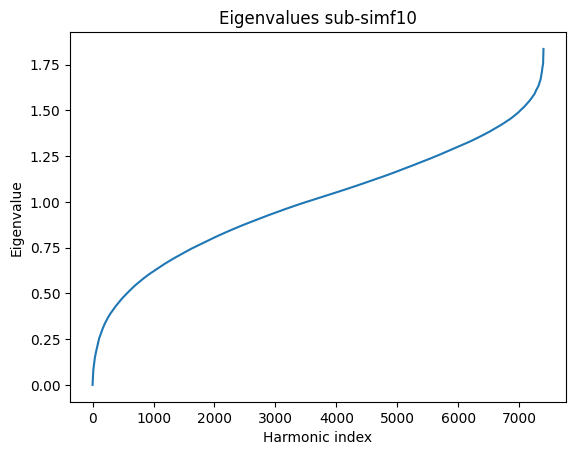

In [3]:
mm.viz.plot_eigval(eigval, subject=sub)

Harmonics.

In [4]:
%%bash
mindmap-viz eigvec --config "../../config.yml" --subject simf10